# Task 2 - Other approaches and improvements on MoNuSeg

**Computer Vision II — Master in Artificial Intelligence (2025/2026)**

This notebooks has the intention to explore other approaches and improvements on the MoNuSeg dataset, beyond the UNet-based segmentation model implemented in Task 1. We will focus on two main directions:


**Translation direction:** `label map (binary nuclei mask)  →  realistic histology image`.

Pipeline:
1. Load and process the MoNuSeg dataset (split each PNG into the two halves).
2. Split into train / validation / test (70 / 15 / 15).
3. Define 

In [1]:
import os
import os
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")
os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("MKL_NUM_THREADS", "1")

import random
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision import transforms
from torchvision.utils import make_grid

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

def resolve_device():
    if torch.cuda.is_available():
        return torch.device("cuda:0")
    if hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")

DEVICE = resolve_device()
print("Device:", DEVICE)
print("CUDA available:", torch.cuda.is_available())
print("MPS available:", hasattr(torch.backends, "mps") and torch.backends.mps.is_available())

# ---------- Hyperparameters ----------
DATA_DIR     = Path("MoNuSeg")
IMG_SIZE     = 256          # Pix2Pix uses 256x256; MoNuSeg halves are 200x200 -> resize
BATCH_SIZE   = 16
NUM_WORKERS  = 0            # set >0 if running on Linux/Mac; on Windows keep at 0
EPOCHS       = 200
LR           = 2e-4
BETAS        = (0.5, 0.999)
LAMBDA_L1    = 100.0        # weight of the L1 reconstruction loss
NGF          = 64           # base number of generator filters
NDF          = 64           # base number of discriminator filters
SAVE_DIR     = Path("checkpoints_baseline")
SAVE_DIR.mkdir(exist_ok=True)
SAMPLES_DIR  = Path("samples_baseline")
SAMPLES_DIR.mkdir(exist_ok=True)

Device: mps
CUDA available: False
MPS available: True


## 2. Dataset

Each PNG file in `MoNuSeg/` is a horizontally concatenated pair: the **left
half** is the real histopathology image (RGB) and the **right half** is the
corresponding **binary nuclei mask**. We load the file, split the two halves,
resize them to 256×256 and normalize each tensor to the range `[-1, 1]` so the
generator can use a `tanh` output, as in the original Pix2Pix.

In [2]:
class MoNuSegDataset(Dataset):
    """Paired dataset for MoNuSeg.

    Returns (label_map, real_image) tensors in [-1, 1] with shape (3, H, W).
    The label map (binary mask) is replicated to 3 channels so the generator
    has a fixed input-channel count, matching the standard Pix2Pix layout.
    """

    def __init__(self, root: Path, img_size: int = 256):
        self.files = sorted(Path(root).glob("*.png"))
        if len(self.files) == 0:
            raise FileNotFoundError(f"No PNG files found in {root}")
        self.img_size = img_size
        self.to_tensor = transforms.Compose([
            transforms.Resize((img_size, img_size), interpolation=transforms.InterpolationMode.BICUBIC),
            transforms.ToTensor(),                                    # [0, 1]
            transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),   # [-1, 1]
        ])

    def __len__(self):
        return len(self.files)

    def __getitem__(self, idx):
        img = Image.open(self.files[idx]).convert("RGB")
        w, h = img.size
        half = w // 2
        real  = img.crop((0,    0, half, h))   # left  -> realistic histology
        label = img.crop((half, 0, w,    h))   # right -> nuclei mask
        return self.to_tensor(label), self.to_tensor(real)


# Build dataset and 70/15/15 split
full_dataset = MoNuSegDataset(DATA_DIR, img_size=IMG_SIZE)
n_total = len(full_dataset)
n_train = int(0.70 * n_total)
n_val   = int(0.15 * n_total)
n_test  = n_total - n_train - n_val

indices = list(range(n_total))
rng = np.random.default_rng(SEED)
rng.shuffle(indices)
train_idx = indices[:n_train]
val_idx   = indices[n_train:n_train + n_val]
test_idx  = indices[n_train + n_val:]

train_set = Subset(full_dataset, train_idx)
val_set   = Subset(full_dataset, val_idx)
test_set  = Subset(full_dataset, test_idx)

train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, drop_last=True)
val_loader   = DataLoader(val_set,   batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=NUM_WORKERS)
test_loader  = DataLoader(test_set,  batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=NUM_WORKERS)

print(f"Dataset size: {n_total}")
print(f"  train: {len(train_set)}  | val: {len(val_set)}  | test: {len(test_set)}")
print(f"  batches/epoch (train): {len(train_loader)}")

Dataset size: 500
  train: 350  | val: 75  | test: 75
  batches/epoch (train): 21


### 2.1 Visual sanity check

A few random pairs from the training split to confirm that the left half is the
real histology image and the right half is the nuclei mask.

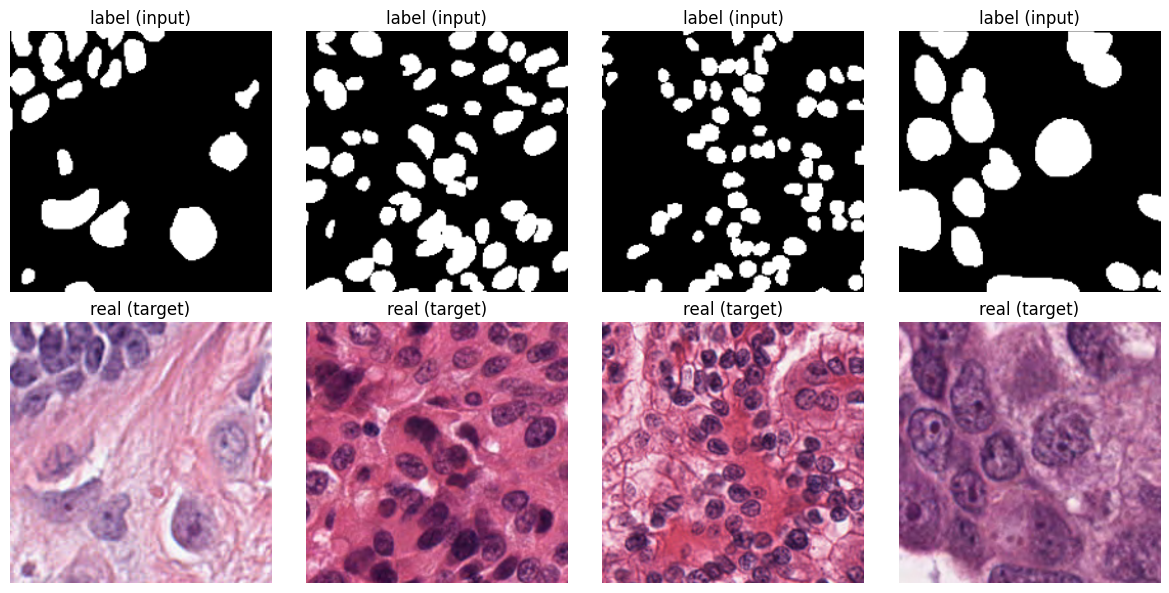

In [3]:
def denorm(t: torch.Tensor) -> torch.Tensor:
    """Map a tensor from [-1, 1] back to [0, 1] for display."""
    return (t.clamp(-1, 1) + 1.0) / 2.0


fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for col in range(4):
    label, real = train_set[col]
    axes[0, col].imshow(denorm(label).permute(1, 2, 0).numpy())
    axes[0, col].set_title(f"label (input)")
    axes[0, col].axis("off")
    axes[1, col].imshow(denorm(real).permute(1, 2, 0).numpy())
    axes[1, col].set_title(f"real (target)")
    axes[1, col].axis("off")
plt.tight_layout()
plt.show()

## 3. Pix2PixHD — arquitectura y entrenamiento

En las siguientes celdas importamos `pix2pixHD`, creamos las opciones de entrenamiento (sin instance maps), inicializamos el modelo y ejecutamos un bucle de entrenamiento adaptado al dataset ya definido en este notebook.

In [ ]:
# Crear opciones de entrenamiento (sin argparse, configuración directa desde notebook)
from options.train_options import TrainOptions
from models.models import create_model
from torch.autograd import Variable
import json

# Crear instancia de opciones y configurar directamente
opt = TrainOptions()
opt.isTrain = True
opt.device = DEVICE  # el modelo respetará este dispositivo explícitamente
opt.gpu_ids = [0] if DEVICE.type == 'cuda' else []
opt.checkpoints_dir = 'checkpoints_pix2pixHD'
opt.name = 'pix2pixHD_monusg'
opt.no_instance = True  # desactivar instance maps y embeddings
opt.verbose = False
opt.display_freq = 200
opt.print_freq = 200
opt.save_latest_freq = 5000
opt.save_epoch_freq = 5
opt.niter = 30
opt.niter_decay = 0
opt.lr = LR
opt.batchSize = BATCH_SIZE
opt.no_vgg_loss = False  # usar VGG loss (parte de la pérdida del artículo)
opt.no_ganFeat_loss = False  # usar GAN feature matching loss

# Parse para imprimir opciones y guardar config
opt = opt.parse(save=False)

print('Prepared options:', opt.name, opt.checkpoints_dir)

------------ Options -------------
batchSize: 16
beta1: 0.5
checkpoints_dir: checkpoints_pix2pixHD
continue_train: False
data_type: 32
dataroot: ./datasets/cityscapes/
debug: False
device: mps
display_freq: 200
display_winsize: 512
feat_num: 3
fineSize: 512
fp16: False
gpu_ids: []
input_nc: 3
instance_feat: False
isTrain: True
label_feat: False
label_nc: 35
lambda_feat: 10.0
loadSize: 1024
load_features: False
load_pretrain: 
local_rank: 0
lr: 0.0002
max_dataset_size: inf
model: pix2pixHD
nThreads: 2
n_blocks_global: 9
n_blocks_local: 3
n_clusters: 10
n_downsample_E: 4
n_downsample_global: 4
n_layers_D: 3
n_local_enhancers: 1
name: pix2pixHD_monusg
ndf: 64
nef: 16
netG: global
ngf: 64
niter: 30
niter_decay: 0
niter_fix_global: 0
no_flip: False
no_ganFeat_loss: False
no_html: False
no_instance: True
no_lsgan: False
no_vgg_loss: False
norm: instance
num_D: 2
output_nc: 3
phase: train
pool_size: 0
print_freq: 200
resize_or_crop: scale_width
save_epoch_freq: 5
save_latest_freq: 5000
serial

In [5]:
# Crear e inicializar el modelo
model = create_model(opt)
# Si está envuelto por DataParallel, trabajar con .module para obtener atributos
net = model.module if hasattr(model, 'module') else model

# Obtener optimizadores desde el objeto de modelo (pix2pixHD los crea en initialize)
if hasattr(net, 'optimizer_G') and hasattr(net, 'optimizer_D'):
    optimizer_G, optimizer_D = net.optimizer_G, net.optimizer_D
else:
    raise RuntimeError('El modelo pix2pixHD no expone optimizadores (optimizer_G/optimizer_D)')

print('Model created and optimizers initialized')
print(f'Model device: {getattr(net, "device", None)}')
print(f'Discriminator GPU IDs: {opt.gpu_ids}')

GlobalGenerator(
  (model): Sequential(
    (0): ReflectionPad2d((3, 3, 3, 3))
    (1): Conv2d(35, 64, kernel_size=(7, 7), stride=(1, 1))
    (2): InstanceNorm2d(64, eps=1e-05, momentum=0.1, affine=False, track_running_stats=False)
    (3): ReLU(inplace=True)
    (4): Conv2d(64, 128, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (5): InstanceNorm2d(128, eps=1e-05, momentum=0.1, affine=False, track_running_stats=False)
    (6): ReLU(inplace=True)
    (7): Conv2d(128, 256, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (8): InstanceNorm2d(256, eps=1e-05, momentum=0.1, affine=False, track_running_stats=False)
    (9): ReLU(inplace=True)
    (10): Conv2d(256, 512, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (11): InstanceNorm2d(512, eps=1e-05, momentum=0.1, affine=False, track_running_stats=False)
    (12): ReLU(inplace=True)
    (13): Conv2d(512, 1024, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (14): InstanceNorm2d(1024, eps=1e-05, momentum=0.1, aff

/Users/davidflorezmazuera/Library/CloudStorage/SynologyDrive-dfm/Universidad/MIA/cv2_project/cv2-project-private/.venv/lib/python3.12/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/Users/davidflorezmazuera/Library/CloudStorage/SynologyDrive-dfm/Universidad/MIA/cv2_project/cv2-project-private/.venv/lib/python3.12/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=VGG19_Weights.IMAGENET1K_V1`. You can also use `weights=VGG19_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Model created and optimizers initialized
Model device: mps
Discriminator GPU IDs: []


In [6]:
# Bucle de entrenamiento (adaptado del script original, usando los DataLoaders del notebook)
import time

# Historial para trackear pérdidas
history = {"g_loss": [], "d_loss": []}

total_steps = 0
start_time = time.time()
for epoch in range(1, opt.niter + opt.niter_decay + 1):
    epoch_g, epoch_d = 0.0, 0.0
    net.train()
    for i, (label, real) in enumerate(train_loader):
        label = label.to(DEVICE)
        real = real.to(DEVICE)

        # forward & compute losses via la API del modelo (sin instancia ni feat maps)
        save_fake = False
        losses, generated = model(Variable(label), None, Variable(real), None, infer=save_fake)

        # promedio por dispositivo/tensor
        losses = [ torch.mean(x) if not isinstance(x, int) else x for x in losses ]
        loss_names = getattr(net, 'loss_names', None)
        if loss_names is None:
            # fallback: esperar nombres de losses estándar
            loss_names = ['G_GAN', 'G_GAN_Feat', 'G_VGG', 'D_real', 'D_fake']
        loss_dict = dict(zip(loss_names[:len(losses)], losses))

        # Construir losses agregadas para G y D a partir de prefijos
        loss_D = sum(v for k, v in loss_dict.items() if k.startswith('D_'))
        loss_G = sum(v for k, v in loss_dict.items() if k.startswith('G_'))

        # actualizar generador
        optimizer_G.zero_grad()
        loss_G.backward()
        optimizer_G.step()

        # actualizar discriminador
        optimizer_D.zero_grad()
        loss_D.backward()
        optimizer_D.step()

        epoch_g += loss_G.item() if isinstance(loss_G, torch.Tensor) else float(loss_G)
        epoch_d += loss_D.item() if isinstance(loss_D, torch.Tensor) else float(loss_D)
        total_steps += 1

    n_batches = len(train_loader)
    history["g_loss"].append(epoch_g / n_batches)
    history["d_loss"].append(epoch_d / n_batches)

    elapsed = time.time() - start_time
    print(f'Epoch {epoch:03d}/{opt.niter + opt.niter_decay} | G {history["g_loss"][-1]:.4f} | D {history["d_loss"][-1]:.4f} | {elapsed/60:.1f} min')

    # Guardar checkpoints periódicamente
    if epoch % opt.save_epoch_freq == 0:
        net.save('latest')
        net.save(epoch)

print('Training complete.')

RuntimeError: MPS backend out of memory (MPS allocated: 8.88 GiB, other allocations: 33.38 MiB, max allowed: 9.07 GiB). Tried to allocate 256.00 MiB on private pool. Use PYTORCH_MPS_HIGH_WATERMARK_RATIO=0.0 to disable upper limit for memory allocations (may cause system failure).

### 4.1 Loss curves

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(history["g_loss"], label="G loss", linewidth=2)
ax.plot(history["d_loss"], label="D loss", linewidth=2)
ax.set_xlabel("Epoch")
ax.set_ylabel("Loss")
ax.set_title("Pix2PixHD Training Losses")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 5. Evaluation on the test set

We evaluate the trained Pix2PixHD model on the test split using:

* **L1** (mean absolute error in `[0, 1]`),
* **PSNR** (higher is better),
* **SSIM** (structural similarity, higher is better),
* **FID** (Fréchet Inception Distance, lower is better — perceptual realism).

In [ ]:
try:
    from torchmetrics.image import StructuralSimilarityIndexMeasure, PeakSignalNoiseRatio
    from torchmetrics.image.fid import FrechetInceptionDistance
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', 'torchmetrics[image]', 'torch-fidelity'])
    from torchmetrics.image import StructuralSimilarityIndexMeasure, PeakSignalNoiseRatio
    from torchmetrics.image.fid import FrechetInceptionDistance

# Preparar métricas
ssim_metric = StructuralSimilarityIndexMeasure(data_range=1.0).to(DEVICE)
psnr_metric = PeakSignalNoiseRatio(data_range=1.0).to(DEVICE)
fid_metric = FrechetInceptionDistance(feature=2048, normalize=True).to('cpu')

net.eval()
l1_total, n = 0.0, 0
with torch.no_grad():
    for label, real in test_loader:
        label = label.to(DEVICE)
        real = real.to(DEVICE)
        # crear inst maps vacíos (no_instance True evita usar mapas)
        inst = torch.zeros(label.size(0), 1, label.size(2), label.size(3)).to(DEVICE)
        fake = net.inference(Variable(label), Variable(inst), image=None)

        fake01 = (fake.clamp(-1, 1) + 1.0) / 2.0
        real01 = (real.clamp(-1, 1) + 1.0) / 2.0

        l1_total += torch.mean(torch.abs(fake01 - real01)).item() * label.size(0)
        n += label.size(0)
        ssim_metric.update(fake01, real01)
        psnr_metric.update(fake01, real01)
        fid_metric.update(real01.to('cpu'), real=True)
        fid_metric.update(fake01.to('cpu'), real=False)

results = {
    'L1':   l1_total / max(n, 1),
    'PSNR': psnr_metric.compute().item(),
    'SSIM': ssim_metric.compute().item(),
    'FID':  fid_metric.compute().item(),
}
print('\nTest-set metrics (Pix2PixHD on MoNuSeg)')
print('-' * 48)
for k, v in results.items():
    print(f'  {k:<5}: {v:.4f}')

### 5.1 Qualitative results

Side-by-side comparison `label  |  generated  |  real` on a handful of test images.

In [ ]:
net.eval()
n_show = 6
fig, axes = plt.subplots(n_show, 3, figsize=(9, 3 * n_show))
with torch.no_grad():
    for i in range(n_show):
        label, real = test_set[i]
        inst = torch.zeros(1, 1, label.size(1), label.size(2)).to(DEVICE)
        fake = net.inference(Variable(label.unsqueeze(0).to(DEVICE)), Variable(inst), image=None).squeeze(0).cpu()
        for j, (img, title) in enumerate([
            (denorm(label), "label"),
            (denorm(fake),  "generated"),
            (denorm(real),  "real"),
        ]):
            axes[i, j].imshow(img.permute(1, 2, 0).numpy())
            axes[i, j].axis("off")
            if i == 0:
                axes[i, j].set_title(title)
plt.tight_layout()
plt.show()

### 5.2 Persist the metrics

Save the test-set metrics to JSON for comparison with Task 1 baseline.

In [ ]:
import json

summary = {
    "dataset": "MoNuSeg",
    "model":   "Pix2PixHD (no instance maps)",
    "epochs":  opt.niter,
    "img_size": IMG_SIZE,
    "batch_size": BATCH_SIZE,
    "test_metrics": {k: float(v) for k, v in results.items()},
}

out_dir = Path(opt.checkpoints_dir) / opt.name
out_dir.mkdir(parents=True, exist_ok=True)
metrics_file = out_dir / 'test_metrics_pix2pixHD.json'

with open(metrics_file, 'w') as f:
    json.dump(summary, f, indent=2)

print(f"Saved metrics to {metrics_file}")
print(json.dumps(summary, indent=2))